In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, glob, zipfile, urllib.request

URL = "https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_drive_0005/2011_09_26_drive_0005_extract.zip"
os.makedirs("/kaggle/working/kitti", exist_ok=True)
zp = "/kaggle/working/kitti/d0005.zip"
if not os.path.exists(zp):
    urllib.request.urlretrieve(URL, zp)
    zipfile.ZipFile(zp).extractall("/kaggle/working/kitti")

for p in glob.glob("/kaggle/working/kitti/**/timestamps*.txt", recursive=True):
    print(p)

/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/image_03/timestamps.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/image_00/timestamps.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/image_02/timestamps.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/oxts/timestamps.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/image_01/timestamps.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/velodyne_points/timestamps_end.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/velodyne_points/timestamps.txt
/kaggle/working/kitti/2011_09_26/2011_09_26_drive_0005_extract/velodyne_points/timestamps_start.txt


camera (image_00): n=160  mean=103.260ms  std=0.910ms  min=100.190  max=106.630
IMU (oxts): n=1648  mean=10.000ms  std=4.179ms  min=-50.190  max=129.814
LiDAR (velodyne): n=158  mean=103.267ms  std=0.116ms  min=102.746  max=103.692


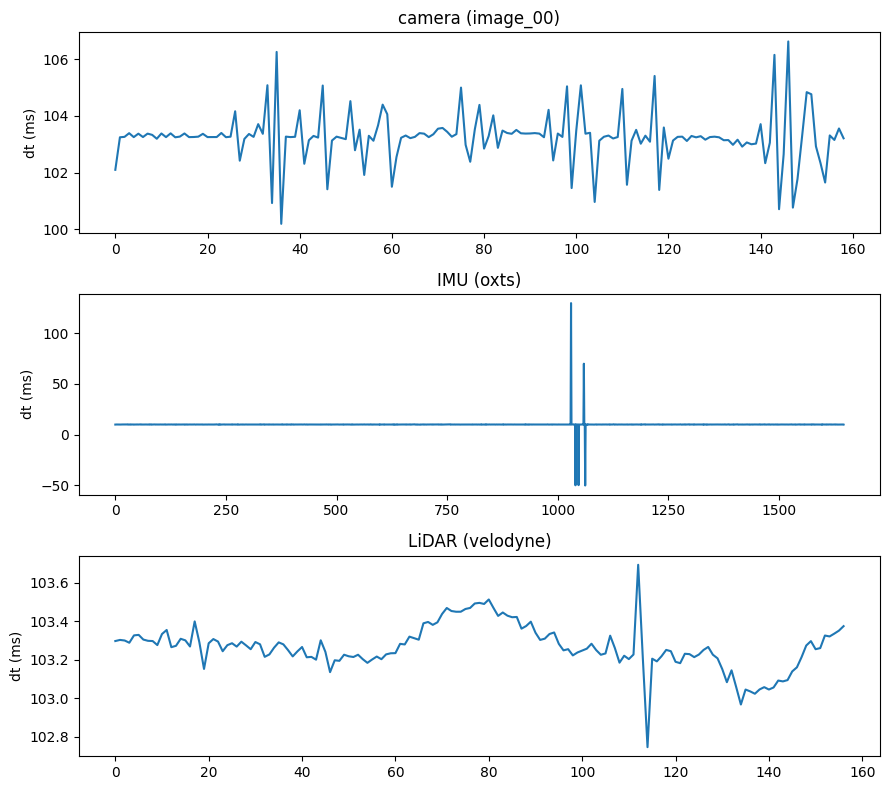

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

root = glob.glob("/kaggle/working/kitti/*/*_extract")[0]
sensors = {
    "camera (image_00)": f"{root}/image_00/timestamps.txt",
    "IMU (oxts)":        f"{root}/oxts/timestamps.txt",
    "LiDAR (velodyne)":  f"{root}/velodyne_points/timestamps.txt",
}

ts = {}
for name, path in sensors.items():
    t = pd.to_datetime(pd.read_csv(path, header=None)[0]).astype("int64").values  # ns
    ts[name] = t
    dt_ms = np.diff(t) / 1e6
    print(f"{name}: n={len(t)}  mean={dt_ms.mean():.3f}ms  std={dt_ms.std():.3f}ms  "
          f"min={dt_ms.min():.3f}  max={dt_ms.max():.3f}")

fig, ax = plt.subplots(3, 1, figsize=(9, 8))
for a, (name, t) in zip(ax, ts.items()):
    a.plot(np.diff(t) / 1e6)
    a.set_title(name); a.set_ylabel("dt (ms)")
plt.tight_layout(); plt.show()

In [3]:
t = ts["IMU (oxts)"]
d = np.diff(t) / 1e6
bad = np.where((d < 0) | (d > 15))[0]
print("anomalous intervals at idx:", bad, "\n", d[bad].round(2))
print("non-monotonic count:", (d < 0).sum())

lo, hi = max(bad.min() - 3, 0), bad.max() + 5
w = pd.DataFrame({"idx": np.arange(lo, hi),
                  "t_ms_from_start": ((t[lo:hi] - t[0]) / 1e6).round(2)})
w["dt_ms"] = w["t_ms_from_start"].diff().round(2)
print(w.to_string(index=False))

# start-time offsets between sensors
t0 = min(v[0] for v in ts.values())
for k, v in ts.items():
    print(f"{k}: starts {(v[0]-t0)/1e6:.1f} ms after earliest, "
          f"duration {(v[-1]-v[0])/1e9:.2f} s")

anomalous intervals at idx: [1030 1040 1047 1059 1062] 
 [129.81 -49.99 -49.84  70.01 -50.19]
non-monotonic count: 3
 idx  t_ms_from_start  dt_ms
1027         10270.43    NaN
1028         10280.51  10.08
1029         10290.50   9.99
1030         10300.62  10.12
1031         10430.43 129.81
1032         10440.42   9.99
1033         10450.43  10.01
1034         10460.42   9.99
1035         10470.43  10.01
1036         10480.59  10.16
1037         10490.44   9.85
1038         10500.43   9.99
1039         10510.46  10.03
1040         10520.42   9.96
1041         10470.43 -49.99
1042         10480.59  10.16
1043         10490.44   9.85
1044         10500.43   9.99
1045         10510.46  10.03
1046         10520.42   9.96
1047         10530.43  10.01
1048         10480.59 -49.84
1049         10490.44   9.85
1050         10500.43   9.99
1051         10510.46  10.03
1052         10520.42   9.96
1053         10530.43  10.01
1054         10540.42   9.99
1055         10550.44  10.02
1056         

In [4]:
oxts_files = sorted(glob.glob(f"{root}/oxts/data/*.txt"))
print("oxts files:", len(oxts_files), "| timestamps:", len(ts["IMU (oxts)"]))

payload = np.array([np.loadtxt(f) for f in oxts_files])   # (N, 30)
t = ts["IMU (oxts)"]

vals, counts = np.unique(t, return_counts=True)
dups = vals[counts > 1]
print("unique stamps:", len(vals), "of", len(t), "| stamps appearing >1x:", len(dups))

same = [np.allclose(payload[np.where(t == v)[0]], payload[np.where(t == v)[0][0]])
        for v in dups]
print("duplicated stamps with identical payload:", sum(same), "/", len(same))

for v in dups[:6]:
    print(np.where(t == v)[0])

oxts files: 1648 | timestamps: 1648
unique stamps: 1633 of 1648 | stamps appearing >1x: 10
duplicated stamps with identical payload: 10 / 10
[1035 1041]
[1036 1042 1048]
[1037 1043 1049]
[1038 1044 1050]
[1039 1045 1051]
[1040 1046 1052]


In [5]:
t = ts["IMU (oxts)"]
u, keep = np.unique(t, return_index=True)       # sorted by stamp, first occurrence kept
t_clean, imu_clean = t[keep], payload[keep]
ts["IMU (oxts)"] = t_clean

d = np.diff(t_clean) / 1e6
print(f"{len(t_clean)} samples | dt min {d.min():.2f}  max {d.max():.2f} ms")
for g in np.where(d > 15)[0]:
    print(f"gap after idx {g}: {d[g]:.1f} ms  (~{round(d[g]/10) - 1} samples missing)")

np.savez("/kaggle/working/imu_clean.npz", t_ns=t_clean, data=imu_clean)

1633 samples | dt min 9.77  max 129.81 ms
gap after idx 1030: 129.8 ms  (~12 samples missing)
gap after idx 1047: 40.0 ms  (~3 samples missing)


camera->LiDAR: mean -15.1  std 18.1  min -20.4  max 188.7 ms
camera->IMU:   mean 0.5  std 5.5  min -8.1  max 43.0 ms


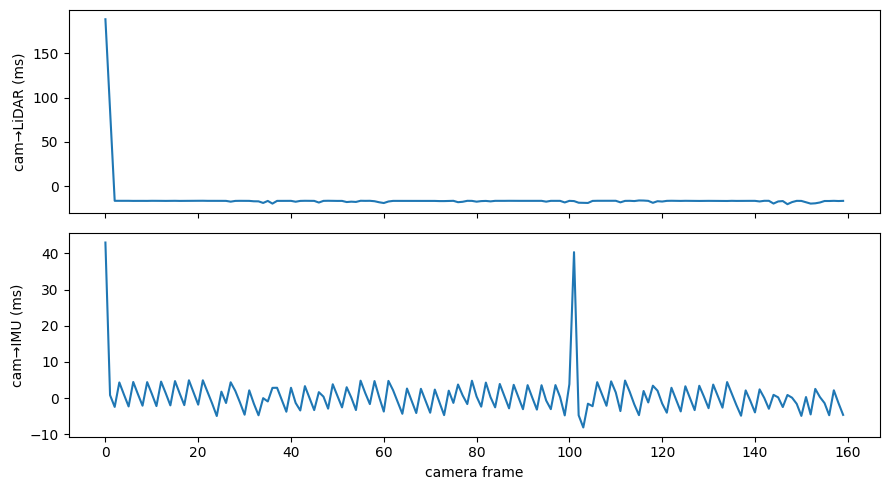

In [6]:
def nearest_offset_ms(a, b):
    """For each stamp in a, signed offset to the nearest stamp in b."""
    i = np.clip(np.searchsorted(b, a), 1, len(b) - 1)
    l, r = b[i - 1], b[i]
    nearest = np.where(np.abs(a - l) < np.abs(a - r), l, r)
    return (nearest - a) / 1e6

cam, lid, imu = ts["camera (image_00)"], ts["LiDAR (velodyne)"], ts["IMU (oxts)"]
off_lid = nearest_offset_ms(cam, lid)
off_imu = nearest_offset_ms(cam, imu)
print(f"camera->LiDAR: mean {off_lid.mean():.1f}  std {off_lid.std():.1f}  "
      f"min {off_lid.min():.1f}  max {off_lid.max():.1f} ms")
print(f"camera->IMU:   mean {off_imu.mean():.1f}  std {off_imu.std():.1f}  "
      f"min {off_imu.min():.1f}  max {off_imu.max():.1f} ms")

fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(off_lid); ax[0].set_ylabel("cam→LiDAR (ms)")
ax[1].plot(off_imu); ax[1].set_ylabel("cam→IMU (ms)"); ax[1].set_xlabel("camera frame")
plt.tight_layout(); plt.show()

In [7]:
def trim(off, t_cam, other):
    ok = (t_cam >= other[0]) & (t_cam <= other[-1])
    return off[ok], t_cam[ok]

for name, other, off in [("LiDAR", lid, off_lid), ("IMU", imu, off_imu)]:
    o, tc = trim(off, cam, other)
    if name == "IMU":                       # also drop the gap-induced spike
        m = np.abs(o) < 10
        o, tc = o[m], tc[m]
    x = (tc - tc[0]) / 1e9                  # seconds
    slope, _ = np.polyfit(x, o, 1)          # ms per second
    print(f"cam→{name}: n={len(o)}  mean {o.mean():.2f}  std {o.std():.2f} ms  "
          f"| slope {slope:.4f} ms/s = {slope*1000:.0f} ppm")

cam→LiDAR: n=157  mean -17.03  std 0.78 ms  | slope -0.0333 ms/s = -33 ppm
cam→IMU: n=158  mean 0.01  std 2.94 ms  | slope -0.0944 ms/s = -94 ppm


linear slope -33 ppm  ± 26 ppm (95%)
residual std: linear 0.767 ms | quadratic 0.766 ms
block-bootstrap 95% CI (ppm): [-74.  22.]


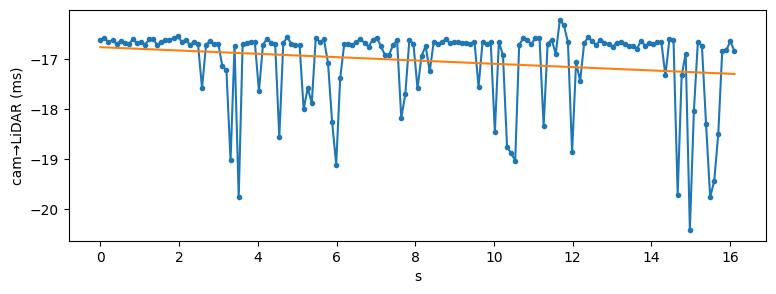

In [8]:
o, tc = trim(off_lid, cam, lid)
x = (tc - tc[0]) / 1e9
n = len(x)

p1 = np.polyfit(x, o, 1);  r1 = o - np.polyval(p1, x)
p2 = np.polyfit(x, o, 2);  r2 = o - np.polyval(p2, x)
se = r1.std(ddof=2) / (x.std() * np.sqrt(n))        # std error of slope, ms/s
print(f"linear slope {p1[0]*1000:.0f} ppm  ± {2*se*1000:.0f} ppm (95%)")
print(f"residual std: linear {r1.std():.3f} ms | quadratic {r2.std():.3f} ms")

# bootstrap by blocks (keeps the wander's correlation)
rng = np.random.default_rng(0); B = 10
sl = []
for _ in range(1000):
    starts = rng.integers(0, n - B, n // B + 1)
    idx = np.concatenate([np.arange(s, s + B) for s in starts])[:n]
    sl.append(np.polyfit(x[idx], o[idx], 1)[0] * 1000)
print("block-bootstrap 95% CI (ppm):", np.percentile(sl, [2.5, 97.5]).round(0))

plt.figure(figsize=(9, 3)); plt.plot(x, o, ".-"); plt.plot(x, np.polyval(p1, x))
plt.xlabel("s"); plt.ylabel("cam→LiDAR (ms)"); plt.show()

In [9]:
from scipy.stats import theilslopes

def robust_slope_ppm(off, tc):
    x = (tc - tc[0]) / 1e9
    s, _, lo, hi = theilslopes(off, x)
    return s * 1e3, lo * 1e3, hi * 1e3        # ms/s -> ppm

def inject(t_ns, offset_ms=0.0, drift_ppm=0.0, jitter_ms=0.0, drop_frac=0.0, seed=0):
    """Corrupt one stream's timestamps with known ground truth."""
    rng = np.random.default_rng(seed)
    t0 = t_ns[0]
    rel = (t_ns - t0).astype(np.float64)       # relative ns avoids float64 precision loss
    new = rel + offset_ms*1e6 + drift_ppm*1e-6*rel + rng.normal(0, jitter_ms*1e6, len(rel))
    keep = rng.random(len(rel)) >= drop_frac
    out = np.sort(np.round(new[keep]).astype(np.int64) + t0)
    return out, dict(offset_ms=offset_ms, drift_ppm=drift_ppm,
                     jitter_ms=jitter_ms, drop_frac=drop_frac)

# 1) robust baseline on the real data
o, tc = trim(off_lid, cam, lid)
s, lo, hi = robust_slope_ppm(o, tc)
print(f"REAL cam→LiDAR robust slope: {s:.0f} ppm  [{lo:.0f}, {hi:.0f}]")

# 2) sanity test: inject known drift into LiDAR, recover it
for drift in [0, 200, 500, 1000]:
    lid_bad, truth = inject(lid, offset_ms=10, drift_ppm=drift, jitter_ms=0.5, seed=1)
    off = nearest_offset_ms(cam, lid_bad)
    o2, tc2 = trim(off, cam, lid_bad)
    s2, lo2, hi2 = robust_slope_ppm(o2, tc2)
    print(f"injected {drift:5d} ppm -> recovered {s2-s:7.0f} ppm  [{lo2-s:.0f}, {hi2-s:.0f}]")

REAL cam→LiDAR robust slope: -5 ppm  [-10, -1]
injected     0 ppm -> recovered     -22 ppm  [-46, 2]
injected   200 ppm -> recovered     178 ppm  [154, 202]
injected   500 ppm -> recovered     479 ppm  [457, 503]
injected  1000 ppm -> recovered     979 ppm  [957, 1003]


In [10]:
def run(drift, seed, jitter):
    bad, _ = inject(lid, offset_ms=10, drift_ppm=drift, jitter_ms=jitter, seed=seed)
    off = nearest_offset_ms(cam, bad)
    o2, tc2 = trim(off, cam, bad)
    return robust_slope_ppm(o2, tc2)[0] - s

print("no injected jitter (should recover ~exactly, any error is pairing/estimator bias):")
for d in [0, 20, 200]:
    print(f"  {d:4d} ppm -> {run(d, 0, 0.0):7.1f}")

print("\n0.5 ms injected jitter, 200 seeds:")
for d in [0, 20, 50, 200]:
    r = np.array([run(d, sd, 0.5) for sd in range(200)])
    print(f"  {d:4d} ppm -> mean {r.mean():7.1f}   std {r.std():5.1f}   "
          f"95% range [{np.percentile(r, 2.5):.0f}, {np.percentile(r, 97.5):.0f}]")

no injected jitter (should recover ~exactly, any error is pairing/estimator bias):
     0 ppm ->    -0.0
    20 ppm ->    20.0
   200 ppm ->   200.0

0.5 ms injected jitter, 200 seeds:
     0 ppm -> mean   -14.0   std   9.4   95% range [-32, 4]
    20 ppm -> mean     6.0   std   9.4   95% range [-12, 24]
    50 ppm -> mean    36.0   std   9.4   95% range [18, 54]
   200 ppm -> mean   186.0   std   9.4   95% range [168, 204]


In [11]:
# (a) is the -14 ppm bias a Theil-Sen artifact?
o, tc = trim(off_lid, cam, lid)
x = (tc - tc[0]) / 1e9
s_ols = np.polyfit(x, o, 1)[0] * 1e3

def run_ols(drift, seed, jitter=0.5):
    bad, _ = inject(lid, offset_ms=10, drift_ppm=drift, jitter_ms=jitter, seed=seed)
    off = nearest_offset_ms(cam, bad)
    o2, tc2 = trim(off, cam, bad)
    x2 = (tc2 - tc2[0]) / 1e9
    return np.polyfit(x2, o2, 1)[0] * 1e3 - s_ols

r = np.array([run_ols(0, sd) for sd in range(200)])
print(f"OLS, 0 ppm injected: mean {r.mean():.1f}  std {r.std():.1f} ppm")

# (b) synthetic long sessions: how long until 2 ppm is detectable?
def synth_slope(T, drift_ppm, seed, cam_jit=0.8, lid_jit=0.1, dip_p=0.12, dip_ms=1.5):
    rng = np.random.default_rng(seed)
    n = int(T / 0.1033)
    t = np.arange(n) * 103.3e6                              # ns
    cam_t = t + rng.normal(0, cam_jit * 1e6, n)
    cam_t -= (rng.random(n) < dip_p) * rng.exponential(dip_ms * 1e6, n)   # skewed dips
    lid_t = t - 17e6 + drift_ppm * 1e-6 * t + rng.normal(0, lid_jit * 1e6, n)
    off = (lid_t - cam_t) / 1e6
    return np.polyfit(t / 1e9, off, 1)[0] * 1e3             # ppm

print("\nsession  |  bias   noise(std)  | 3*std  | 2 ppm detectable?")
for T in [16, 60, 120, 300, 1200, 3600]:
    r = np.array([synth_slope(T, 2.0, sd) for sd in range(200)])
    print(f"{T:6d}s  | {r.mean()-2:6.2f}   {r.std():7.2f}   | {3*r.std():6.2f} | "
          f"{'yes' if 3*r.std() < 2 else 'no'}")

OLS, 0 ppm injected: mean 0.2  std 8.2 ppm

session  |  bias   noise(std)  | 3*std  | 2 ppm detectable?
    16s  |  -0.02     17.18   |  51.55 | no
    60s  |  -0.13      2.61   |   7.84 | no
   120s  |  -0.02      0.92   |   2.76 | no
   300s  |   0.01      0.23   |   0.69 | yes
  1200s  |   0.00      0.03   |   0.09 | yes
  3600s  |  -0.00      0.01   |   0.02 | yes


In [12]:
def run_ols(drift, seed, jitter=0.5):
    bad, _ = inject(lid, offset_ms=10, drift_ppm=drift, jitter_ms=jitter, seed=seed)
    off = nearest_offset_ms(cam, bad)
    o2, tc2 = trim(off, cam, bad)
    x2 = (tc2 - tc2[0]) / 1e9
    return np.polyfit(x2, o2, 1)[0] * 1e3 - s_ols   # indented

for T in [16, 60, 120, 300, 1200, 3600]:
    r = np.array([synth_slope(T, 2.0, sd) for sd in range(200)])
    print(f"{T:6d}s  | {r.mean()-2:6.2f}   {r.std():7.2f}   | {3*r.std():6.2f} | "
          f"{'yes' if 3*r.std() < 2 else 'no'}")   # inside the loop

    16s  |  -0.02     17.18   |  51.55 | no
    60s  |  -0.13      2.61   |   7.84 | no
   120s  |  -0.02      0.92   |   2.76 | no
   300s  |   0.01      0.23   |   0.69 | yes
  1200s  |   0.00      0.03   |   0.09 | yes
  3600s  |  -0.00      0.01   |   0.02 | yes


In [13]:
def drop_frames(t, frac, burst=1, seed=0):
    """Remove ~frac of frames; burst>1 drops runs of consecutive frames."""
    rng = np.random.default_rng(seed)
    keep = np.ones(len(t), bool)
    starts = np.where(rng.random(len(t)) < frac / burst)[0]
    for s0 in starts:
        keep[s0:s0 + burst] = False
    return t[keep]

def run_drop(frac, burst, seed, drift=0, jitter=0.5):
    bad, _ = inject(lid, offset_ms=10, drift_ppm=drift, jitter_ms=jitter, seed=seed)
    bad = drop_frames(bad, frac, burst, seed)
    off = nearest_offset_ms(cam, bad)
    o2, tc2 = trim(off, cam, bad)
    x2 = (tc2 - tc2[0]) / 1e9
    return np.polyfit(x2, o2, 1)[0] * 1e3 - s_ols, len(o2) / len(off)

print("drop%  burst | mean err   std   | pairs kept")
for frac in [0.0, 0.02, 0.05, 0.10]:
    for burst in [1, 3]:
        if frac == 0 and burst > 1: continue
        res = np.array([run_drop(frac, burst, sd) for sd in range(100)])
        print(f"{frac*100:4.0f}   {burst:3d}   | {res[:,0].mean():7.1f} {res[:,0].std():6.1f}  | {res[:,1].mean():.2f}")

drop%  burst | mean err   std   | pairs kept
   0     1   |     0.4    8.0  | 0.98
   2     1   |    11.5  219.0  | 0.98
   2     3   |     1.3  264.5  | 0.98
   5     1   |     1.2  347.8  | 0.98
   5     3   |    67.0  380.3  | 0.98
  10     1   |    28.7  446.3  | 0.98
  10     3   |    58.3  518.2  | 0.98


In [15]:
def timestamp_health(cam, lid):
    out = {}
    for name, t in [("cam", cam), ("lid", lid)]:
        d = np.diff(t) / 1e6
        med = np.median(d)
        out[f"{name}_drop_frac"] = float((d > 1.5 * med).mean())
        out[f"{name}_jitter_ms"] = float(1.4826 * np.median(np.abs(d - med)))
    off = nearest_offset_ms(cam, lid)
    o, tc = trim(off, cam, lid)
    x = (tc - tc[0]) / 1e9
    p, cov = np.polyfit(x, o, 1, cov=True)
    out["offset_ms"] = float(np.median(o))
    out["drift_ppm"] = float(p[0] * 1e3)
    out["drift_se_ppm"] = float(np.sqrt(cov[0, 0]) * 1e3)      # optimistic: assumes independent errors
    out["drift_detectable"] = abs(out["drift_ppm"]) > 3 * out["drift_se_ppm"]
    pen = (max(out["cam_drop_frac"], out["lid_drop_frac"]) / 0.01          # 1% dropped = 1 unit
           + max(out["cam_jitter_ms"], out["lid_jitter_ms"]) / 1.0          # 1 ms jitter = 1 unit
           + (abs(out["drift_ppm"]) / 10 if out["drift_detectable"] else 0)  # 10 ppm = 1 unit
           + abs(out["offset_ms"]) / 10)                                    # 10 ms = 1 unit
    out["score"] = float(100 * np.exp(-0.25 * pen))
    return out

print(timestamp_health(cam, lid))
bad, _ = inject(lid, offset_ms=10, drift_ppm=200, jitter_ms=1.0, seed=3)
print(timestamp_health(cam, drop_frames(bad, 0.05)))   # should score clearly lower

{'cam_drop_frac': 0.0, 'cam_jitter_ms': 0.1939478015999938, 'lid_drop_frac': 0.0, 'lid_jitter_ms': 0.07550733540001581, 'offset_ms': -16.689291, 'drift_ppm': -33.25162698253862, 'drift_se_ppm': 13.153249962755801, 'drift_detectable': False, 'score': 62.768349689090485}
{'cam_drop_frac': 0.0, 'cam_jitter_ms': 0.1939478015999938, 'lid_drop_frac': 0.0684931506849315, 'lid_jitter_ms': 1.5547900178999952, 'offset_ms': -5.1551, 'drift_ppm': 375.52553039422725, 'drift_se_ppm': 459.5929298213728, 'drift_detectable': False, 'score': 10.753877792263316}


In [16]:
def gated_slope(off, cam, bad, gate_ms=30):
    o2, tc2 = trim(off, cam, bad)
    keep = np.abs(o2 - np.median(o2)) < gate_ms        # mis-pairs sit ~103 ms out, real scatter is ~1 ms
    x = (tc2[keep] - tc2[keep][0]) / 1e9
    return np.polyfit(x, o2[keep], 1)[0] * 1e3, keep.mean()

def run_drop(frac, burst, seed, drift=0, jitter=0.5, gate=True):
    bad, _ = inject(lid, offset_ms=10, drift_ppm=drift, jitter_ms=jitter, seed=seed)
    bad = drop_frames(bad, frac, burst, seed)
    off = nearest_offset_ms(cam, bad)
    sl, kept = gated_slope(off, cam, bad)
    return sl - s_ols, kept

print("drop%  burst | mean err   std   | pairs kept")
for frac in [0.0, 0.02, 0.05, 0.10]:
    for burst in [1, 3]:
        if frac == 0 and burst > 1: continue
        res = np.array([run_drop(frac, burst, sd) for sd in range(100)])
        print(f"{frac*100:4.0f}   {burst:3d}   | {res[:,0].mean():7.1f} {res[:,0].std():6.1f}  | {res[:,1].mean():.2f}")

drop%  burst | mean err   std   | pairs kept
   0     1   |     0.4    8.0  | 1.00
   2     1   |     0.5    8.3  | 0.98
   2     3   |     0.8    8.4  | 0.98
   5     1   |     0.5    8.5  | 0.95
   5     3   |     1.5    9.4  | 0.95
  10     1   |    -0.1    9.8  | 0.90
  10     3   |     1.5   10.2  | 0.90


In [18]:
def timestamp_health(cam, lid, gate_ms=30):
    out = {}
    for name, t in [("cam", cam), ("lid", lid)]:
        d = np.diff(t) / 1e6; med = np.median(d)
        out[f"{name}_drop_frac"] = float((d > 1.5 * med).mean())
        out[f"{name}_jitter_ms"] = float(1.4826 * np.median(np.abs(d - med)))
    off = nearest_offset_ms(cam, lid)
    o, tc = trim(off, cam, lid)
    med = np.median(o); keep = np.abs(o - med) < gate_ms
    x = (tc[keep] - tc[keep][0]) / 1e9
    p, cov = np.polyfit(x, o[keep], 1, cov=True)
    out.update(offset_ms=float(med), rejected_pair_frac=float(1 - keep.mean()),
               drift_ppm=float(p[0] * 1e3), drift_se_ppm=float(np.sqrt(cov[0, 0]) * 1e3))
    out["drift_detectable"] = abs(out["drift_ppm"]) > 3 * out["drift_se_ppm"]
    pen = (max(out["cam_drop_frac"], out["lid_drop_frac"]) / 0.01
           + max(out["cam_jitter_ms"], out["lid_jitter_ms"]) / 1.0
           + (abs(out["drift_ppm"]) / 10 if out["drift_detectable"] else 0)
           + max(0, abs(med) - 40) / 10)
    out["score"] = float(100 * np.exp(-0.25 * pen))
    return out

In [20]:
import glob, numpy as np
# root = your KITTI drive folder, e.g. .../2011_09_26_drive_0005_sync
oxts = np.array([np.loadtxt(f) for f in sorted(glob.glob(f"{root}/oxts/data/*.txt"))])
speed = np.linalg.norm(oxts[:, 8:11], axis=1)       # vf, vl, vu  (m/s)
omega = np.linalg.norm(oxts[:, 17:20], axis=1)      # wx, wy, wz  (rad/s)
v, w = np.sqrt((speed**2).mean()), np.sqrt((omega**2).mean())
print(f"RMS speed {v:.2f} m/s | RMS angular rate {np.degrees(w):.2f} deg/s")

print("\nuncorrected offset | position error | rotation error")
for d in [1, 2, 5, 10, 20, 50]:
    print(f"{d:10d} ms     | {v*d/10:9.2f} cm   | {np.degrees(w)*d/1e3:8.3f} deg")

print("\naccumulated offset from drift (ms) -> position error (cm)")
print("ppm \\ session |   60 s     600 s     3600 s")
for ppm in [1, 5, 50, 200]:
    ms = [ppm * T / 1000 for T in (60, 600, 3600)]
    print(f"{ppm:6d} ppm    | " + "  ".join(f"{m:6.1f} ms/{v*m/10:5.1f} cm" for m in ms))

RMS speed 4.63 m/s | RMS angular rate 9.47 deg/s

uncorrected offset | position error | rotation error
         1 ms     |      0.46 cm   |    0.009 deg
         2 ms     |      0.93 cm   |    0.019 deg
         5 ms     |      2.32 cm   |    0.047 deg
        10 ms     |      4.63 cm   |    0.095 deg
        20 ms     |      9.27 cm   |    0.189 deg
        50 ms     |     23.17 cm   |    0.473 deg

accumulated offset from drift (ms) -> position error (cm)
ppm \ session |   60 s     600 s     3600 s
     1 ppm    |    0.1 ms/  0.0 cm     0.6 ms/  0.3 cm     3.6 ms/  1.7 cm
     5 ppm    |    0.3 ms/  0.1 cm     3.0 ms/  1.4 cm    18.0 ms/  8.3 cm
    50 ppm    |    3.0 ms/  1.4 cm    30.0 ms/ 13.9 cm   180.0 ms/ 83.4 cm
   200 ppm    |   12.0 ms/  5.6 cm   120.0 ms/ 55.6 cm   720.0 ms/333.7 cm


In [22]:
def health_v3(h, T_s, v_rms=4.63, tol_cm=5.0):
    """h = output of timestamp_health(); T_s = session length (s) the verdict is about."""
    ms_per_cm = 10 / v_rms
    worst_ppm = abs(h["drift_ppm"]) + 3 * h["drift_se_ppm"]          # can't rule out anything larger
    h["tol_drift_ppm"]  = tol_cm * ms_per_cm * 1000 / T_s
    h["drift_cost_cm"]  = abs(h["drift_ppm"]) * T_s / 1000 / ms_per_cm
    h["worst_cost_cm"]  = worst_ppm * T_s / 1000 / ms_per_cm
    h["offset_cost_cm_if_ignored"] = abs(h["offset_ms"]) / ms_per_cm
    if h["drift_detectable"] and h["drift_cost_cm"] > tol_cm: h["drift_verdict"] = "EXCEEDS"
    elif h["worst_cost_cm"] <= tol_cm:                        h["drift_verdict"] = "OK"
    else:                                                     h["drift_verdict"] = "UNRESOLVED (session too short)"
    pen = (max(h["cam_drop_frac"], h["lid_drop_frac"]) / 0.01
           + max(h["cam_jitter_ms"], h["lid_jitter_ms"]) / 1.0
           + (h["drift_cost_cm"] / tol_cm if h["drift_verdict"] == "EXCEEDS" else 0))
    h["score"] = float(100 * np.exp(-0.25 * pen))
    return h

h = health_v3(timestamp_health(cam, lid), T_s=600)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in h.items()})

{'cam_drop_frac': 0.0, 'cam_jitter_ms': 0.19, 'lid_drop_frac': 0.0, 'lid_jitter_ms': 0.08, 'offset_ms': -16.69, 'rejected_pair_frac': 0.0, 'drift_ppm': -33.25, 'drift_se_ppm': 13.15, 'drift_detectable': False, 'score': 95.27, 'tol_drift_ppm': 18.0, 'drift_cost_cm': 9.24, 'worst_cost_cm': 20.2, 'offset_cost_cm_if_ignored': 7.73, 'drift_verdict': 'UNRESOLVED (session too short)'}


In [23]:
# --- visual rotation per consecutive camera pair (ORB + essential matrix) ---
import cv2, glob, numpy as np, matplotlib.pyplot as plt

imgs = sorted(glob.glob(f"{root}/image_00/data/*.png"))
assert len(imgs) == len(ts["camera (image_00)"]), (len(imgs), len(ts["camera (image_00)"]))

# approx. P_rect_00 for 2011_09_26 (the extract zip has no calib file; images may be unrectified -> small bias)
fx, cx, cy = 721.5377, 609.5593, 172.8540
K = np.array([[fx, 0, cx], [0, fx, cy], [0, 0, 1.0]])

orb = cv2.ORB_create(2500)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
feats = []
for p in imgs:
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    feats.append(orb.detectAndCompute(im, None))

def pair_rot_deg(fa, fb):
    (ka, da), (kb, db) = fa, fb
    if da is None or db is None: return np.nan, 0
    m = bf.match(da, db)
    if len(m) < 30: return np.nan, 0
    pa = np.float32([ka[x.queryIdx].pt for x in m]); pb = np.float32([kb[x.trainIdx].pt for x in m])
    E, mask = cv2.findEssentialMat(pa, pb, K, cv2.RANSAC, 0.999, 1.0)
    if E is None: return np.nan, 0
    E = E[:3]
    n, R, t, _ = cv2.recoverPose(E, pa, pb, K, mask=mask)
    return float(np.degrees(np.linalg.norm(cv2.Rodrigues(R)[0]))), int(n)

res = [pair_rot_deg(feats[i], feats[i + 1]) for i in range(len(feats) - 1)]
av  = np.array([r[0] for r in res])      # visual rotation angle per camera interval (deg)
inl = np.array([r[1] for r in res])
print(f"{len(av)} pairs | median inliers {np.median(inl):.0f} | visual angle median {np.nanmedian(av):.3f} deg, max {np.nanmax(av):.2f} deg")

159 pairs | median inliers 592 | visual angle median 1.118 deg, max 6.92 deg


valid pairs: 145 of 159 | IMU gaps excluded: 2
baseline correction d0 = -117.00 ms | peak corr 0.427 | corr within 0.02 of peak over [-120, 19] ms


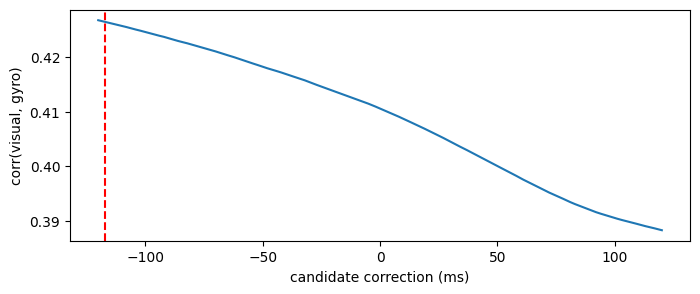

In [24]:
# --- gyro side + estimator ---
from scipy.spatial.transform import Rotation, Slerp

T0 = min(v[0] for v in ts.values())
tc = (ts["camera (image_00)"] - T0) / 1e9          # camera stamps, s
tg = (t_clean - T0) / 1e9                           # cleaned IMU stamps, s
w_body = imu_clean[:, 20:23]                        # wf, wl, wu  (rad/s)
C = np.vstack([np.zeros(3), np.cumsum(0.5 * (w_body[1:] + w_body[:-1]) * np.diff(tg)[:, None], axis=0)])

def gyro_angles_deg(tc_, tau):
    """Rotation magnitude over each camera interval, integrating the gyro on [t_i+tau, t_{i+1}+tau]."""
    a = np.column_stack([np.interp(tc_[1:] + tau, tg, C[:, k]) - np.interp(tc_[:-1] + tau, tg, C[:, k]) for k in range(3)])
    return np.degrees(np.linalg.norm(a, axis=1))

TAUS = np.arange(-0.12, 0.1201, 0.001)
gaps = [(tg[g], tg[g + 1]) for g in np.where(np.diff(tg) > 0.015)[0]]
def near_gap(a, b, m=0.25): return any(a - m < g1 and b + m > g0 for g0, g1 in gaps)

in_range = (tc[:-1] - 0.18 > tg[0]) & (tc[1:] + 0.18 < tg[-1])
valid = in_range & (inl >= 50) & np.isfinite(av) & np.array([not near_gap(tc[i], tc[i + 1]) for i in range(len(av))])
print("valid pairs:", valid.sum(), "of", len(av), "| IMU gaps excluded:", len(gaps))

def corr_curve(tc_, av_, valid_):
    G = np.array([gyro_angles_deg(tc_, t) for t in TAUS])          # (n_tau, n_pairs)
    return G, np.array([np.corrcoef(av_[valid_], g[valid_])[0, 1] for g in G])

def refine(corr, half=3):
    j = int(np.nanargmax(corr)); j = min(max(j, half), len(TAUS) - half - 1)
    sl = slice(j - half, j + half + 1)
    p = np.polyfit(TAUS[sl] * 1e3, corr[sl], 2)
    return -p[1] / (2 * p[0]) if p[0] < 0 else TAUS[j] * 1e3         # ms

G0, corr0 = corr_curve(tc, av, valid)
d0 = refine(corr0)
top = TAUS[corr0 >= np.nanmax(corr0) - 0.02] * 1e3
print(f"baseline correction d0 = {d0:+.2f} ms | peak corr {np.nanmax(corr0):.3f} | "
      f"corr within 0.02 of peak over [{top.min():.0f}, {top.max():.0f}] ms")
plt.figure(figsize=(8, 3)); plt.plot(TAUS * 1e3, corr0); plt.axvline(d0, c="r", ls="--")
plt.xlabel("candidate correction (ms)"); plt.ylabel("corr(visual, gyro)"); plt.show()

In [26]:
# --- validation: inject known stamp shifts, recover them; bootstrap CI on the real baseline ---
shifts = [-50, -20, -10, -5, -2, 0, 2, 5, 10, 20, 50]
print(" inject s | estimate | expected (d0 - s) | error   (ms)")
errs_val = []
for s in shifts:
    _, c = corr_curve(tc + s / 1e3, av, valid)
    est = refine(c); errs_val.append(est - (d0 - s))
    print(f"{s:8d} | {est:8.2f} | {d0 - s:17.2f} | {est - (d0 - s):6.2f}")
print(f"max |error| {np.max(np.abs(errs_val)):.2f} ms")

rng = np.random.default_rng(0)
iv = np.where(valid)[0]
boot = []
for _ in range(300):
    ii = rng.choice(iv, len(iv))
    c = np.array([np.corrcoef(av[ii], g[ii])[0, 1] for g in G0])
    boot.append(refine(c))
lo, med, hi = np.percentile(boot, [2.5, 50, 97.5])
print(f"\nbaseline d0 bootstrap 95% CI: [{lo:.1f}, {hi:.1f}] ms (median {med:.1f}), width {hi - lo:.1f} ms")

 inject s | estimate | expected (d0 - s) | error   (ms)
     -50 |  -124.38 |            -67.00 | -57.38
     -20 |  -117.00 |            -97.00 | -20.00
     -10 |  -117.00 |           -107.00 | -10.00
      -5 |  -128.14 |           -112.00 | -16.14
      -2 |  -162.62 |           -115.00 | -47.62
       0 |  -117.00 |           -117.00 |   0.00
       2 |  -117.00 |           -119.00 |   2.00
       5 |  -141.90 |           -122.00 | -19.90
      10 |  -117.00 |           -127.00 |  10.00
      20 |  -117.00 |           -137.00 |  20.00
      50 |  -117.00 |           -167.00 |  50.00
max |error| 57.38 ms

baseline d0 bootstrap 95% CI: [-1142.3, 117.0] ms (median -117.0), width 1259.3 ms


In [28]:
# --- measured cost of an uncorrected offset on this drive (pose stream only, no filter yet) ---
lat, lon = imu_clean[:, 0], imu_clean[:, 1]
er = 6378137.0; sc = np.cos(np.radians(lat[0]))
P = np.column_stack([sc * er * np.radians(lon),
                     sc * er * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2)),
                     imu_clean[:, 2]])
rot = Rotation.from_euler("ZYX", np.column_stack([imu_clean[:, 5], imu_clean[:, 4], imu_clean[:, 3]]))  # yaw, pitch, roll
slerp = Slerp(tg, rot)
pos_at = lambda t: np.column_stack([np.interp(t, tg, P[:, k]) for k in range(3)])

te = tc[(tc > tg[0] + 0.06) & (tc < tg[-1] - 0.06)]
te = te[[not near_gap(t, t, 0.1) for t in te]]
v_rms = 4.63
print(" offset | pos err RMS (cm) | analytic v*s (cm) | att err RMS (deg)")
for s in [1, 2, 5, 10, 20, 50]:
    dt = s / 1e3
    pe = np.linalg.norm(pos_at(te + dt) - pos_at(te), axis=1)
    ae = (slerp(te + dt) * slerp(te).inv()).magnitude()
    print(f"{s:5d} ms | {100*np.sqrt((pe**2).mean()):15.2f} | {100*v_rms*dt:17.2f} | {np.degrees(np.sqrt((ae**2).mean())):.3f}")

# --- detection sensitivity: how much does the visual-vs-gyro residual grow with misalignment? ---
def resid_rms(s_ms): return np.sqrt(np.mean((av[valid] - gyro_angles_deg(tc + s_ms / 1e3, d0 / 1e3)[valid]) ** 2))
r0 = resid_rms(0)
print(f"\nresidual floor (visual noise + model error): {r0:.3f} deg per interval")
for s in [0, 2, 5, 10, 20, 50]:
    r = resid_rms(s); print(f"  misaligned by {s:3d} ms: residual {r:.3f} deg, excess {np.sqrt(max(r**2 - r0**2, 0)):.3f} deg")

 offset | pos err RMS (cm) | analytic v*s (cm) | att err RMS (deg)
    1 ms |            0.45 |              0.46 | 0.009
    2 ms |            0.91 |              0.93 | 0.019
    5 ms |            2.27 |              2.31 | 0.047
   10 ms |            4.53 |              4.63 | 0.094
   20 ms |            9.04 |              9.26 | 0.188
   50 ms |           22.62 |             23.15 | 0.468

residual floor (visual noise + model error): 0.852 deg per interval
  misaligned by   0 ms: residual 0.852 deg, excess 0.000 deg
  misaligned by   2 ms: residual 0.852 deg, excess 0.012 deg
  misaligned by   5 ms: residual 0.852 deg, excess 0.019 deg
  misaligned by  10 ms: residual 0.852 deg, excess 0.027 deg
  misaligned by  20 ms: residual 0.853 deg, excess 0.039 deg
  misaligned by  50 ms: residual 0.854 deg, excess 0.063 deg


In [29]:
# --- visual rotation vector per consecutive camera pair (ORB + essential matrix) ---
import cv2, glob, numpy as np, matplotlib.pyplot as plt

imgs = sorted(glob.glob(f"{root}/image_00/data/*.png"))
assert len(imgs) == len(ts["camera (image_00)"]), (len(imgs), len(ts["camera (image_00)"]))

fx, cx, cy = 721.5377, 609.5593, 172.8540          # approx P_rect_00, 2011_09_26 (no calib file in the extract zip)
K = np.array([[fx, 0, cx], [0, fx, cy], [0, 0, 1.0]])

orb = cv2.ORB_create(2500)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
H = None
feats = []
for p in imgs:
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    H = im.shape[0]
    mask_roi = np.zeros_like(im); mask_roi[: int(0.8 * H)] = 255          # drop the car hood / bottom strip
    feats.append(orb.detectAndCompute(im, mask_roi))

def pair_rotvec_deg(fa, fb):
    (ka, da), (kb, db) = fa, fb
    if da is None or db is None: return np.full(3, np.nan), 0
    m = bf.match(da, db)
    if len(m) < 30: return np.full(3, np.nan), 0
    pa = np.float32([ka[x.queryIdx].pt for x in m]); pb = np.float32([kb[x.trainIdx].pt for x in m])
    E, mask = cv2.findEssentialMat(pa, pb, K, cv2.RANSAC, 0.999, 1.0)
    if E is None: return np.full(3, np.nan), 0
    n, R, t, _ = cv2.recoverPose(E[:3], pa, pb, K, mask=mask)
    return np.degrees(cv2.Rodrigues(R)[0].ravel()), int(n)    # camera axes: x right, y down, z forward

res = [pair_rotvec_deg(feats[i], feats[i + 1]) for i in range(len(feats) - 1)]
rv  = np.array([r[0] for r in res])      # (n_pairs, 3) deg
inl = np.array([r[1] for r in res])
print(f"{len(rv)} pairs | median inliers {np.median(inl):.0f}")
print("per-axis visual rotation, deg/interval: median |.| =", np.round(np.nanmedian(np.abs(rv), axis=0), 3),
      "| max |.| =", np.round(np.nanmax(np.abs(rv), axis=0), 2))

159 pairs | median inliers 606
per-axis visual rotation, deg/interval: median |.| = [0.108 1.123 0.153] | max |.| = [0.94 5.87 0.63]


valid pairs: 145 of 159 | IMU gaps: 2
corr(visual cam-x (pitch) , gyro yaw) at tau=0: +0.091
corr(visual cam-y (yaw)   , gyro yaw) at tau=0: +0.793
corr(visual cam-z (roll)  , gyro yaw) at tau=0: -0.392
gyro yaw per interval: std 0.928 deg | visual yaw std 1.299 deg
sign convention: visual_yaw = + rv_y

baseline correction d0 = -85.34 ms | peak corr 0.795 at -83 ms | min corr 0.783


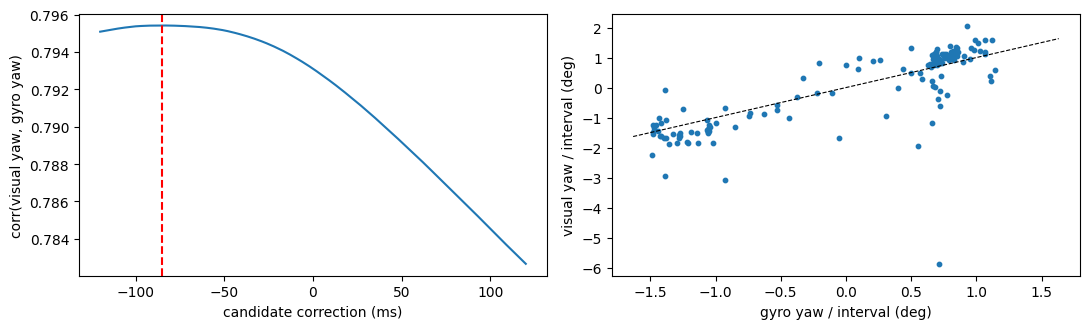

In [30]:
# --- gyro side: signed yaw (about body-up) integrated over each camera interval ---
from scipy.spatial.transform import Rotation, Slerp

T0 = min(v[0] for v in ts.values())
tc = (ts["camera (image_00)"] - T0) / 1e9
tg = (t_clean - T0) / 1e9
wu = imu_clean[:, 22]                                   # rad/s about up
Cz = np.concatenate([[0], np.cumsum(0.5 * (wu[1:] + wu[:-1]) * np.diff(tg))])

def gyro_yaw_deg(tc_, tau):
    return np.degrees(np.interp(tc_[1:] + tau, tg, Cz) - np.interp(tc_[:-1] + tau, tg, Cz))

TAUS = np.arange(-0.12, 0.1201, 0.001)
gaps = [(tg[g], tg[g + 1]) for g in np.where(np.diff(tg) > 0.015)[0]]
def near_gap(a, b, m=0.25): return any(a - m < g1 and b + m > g0 for g0, g1 in gaps)

in_range = (tc[:-1] - 0.18 > tg[0]) & (tc[1:] + 0.18 < tg[-1])
ok = in_range & (inl >= 100) & np.isfinite(rv).all(axis=1) & np.array([not near_gap(tc[i], tc[i + 1]) for i in range(len(rv))])
# reject gross visual outliers: > 6 robust sigmas from the median in the yaw component
y_raw = rv[:, 1]
mad = 1.4826 * np.nanmedian(np.abs(y_raw[ok] - np.nanmedian(y_raw[ok])))
valid = ok & (np.abs(y_raw - np.nanmedian(y_raw[ok])) < 6 * mad + 2.0)
print("valid pairs:", valid.sum(), "of", len(rv), "| IMU gaps:", len(gaps))

# --- SIGNAL CHECK first: is visual yaw related to gyro yaw at all? (tau = 0, both signs) ---
g0 = gyro_yaw_deg(tc, 0.0)
for ax, name in [(0, "cam-x (pitch)"), (1, "cam-y (yaw)"), (2, "cam-z (roll)")]:
    print(f"corr(visual {name:14s}, gyro yaw) at tau=0: {np.corrcoef(rv[valid, ax], g0[valid])[0, 1]:+.3f}")
print(f"gyro yaw per interval: std {g0[valid].std():.3f} deg | visual yaw std {rv[valid,1].std():.3f} deg")

def corr_curve(tc_, y_, valid_):
    G = np.array([gyro_yaw_deg(tc_, t) for t in TAUS])
    return G, np.array([np.corrcoef(y_[valid_], g[valid_])[0, 1] for g in G])

# pick the sign convention from the data (|peak| larger wins)
cp = corr_curve(tc, y_raw, valid)[1]; cn = corr_curve(tc, -y_raw, valid)[1]
SIGN = 1.0 if np.nanmax(cp) >= np.nanmax(cn) else -1.0
vy = SIGN * y_raw
print("sign convention: visual_yaw =", "+" if SIGN > 0 else "-", "rv_y")

def refine(corr, half=12, edge=5):
    """Peak location (ms) from a parabola fit around the maximum; NaN if the max sits at the search boundary or the fit is not concave."""
    c = np.nan_to_num(corr, nan=-1.0); j = int(np.argmax(c))
    if j < edge or j > len(TAUS) - 1 - edge : return np.nan
    sl = slice(j - half, j + half + 1)
    p = np.polyfit(TAUS[sl] * 1e3, c[sl], 2)
    return -p[1] / (2 * p[0]) if p[0] < 0 else np.nan

G0, corr0 = corr_curve(tc, vy, valid)
d0 = refine(corr0)
print(f"\nbaseline correction d0 = {d0:+.2f} ms | peak corr {np.nanmax(corr0):.3f} at {TAUS[np.nanargmax(corr0)]*1e3:+.0f} ms | min corr {np.nanmin(corr0):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(TAUS * 1e3, corr0); ax[0].set_xlabel("candidate correction (ms)"); ax[0].set_ylabel("corr(visual yaw, gyro yaw)")
if np.isfinite(d0): ax[0].axvline(d0, c="r", ls="--")
j0 = np.nanargmax(corr0)
ax[1].scatter(G0[j0][valid], vy[valid], s=10); lim = np.nanmax(np.abs(G0[j0][valid])) * 1.1
ax[1].plot([-lim, lim], [-lim, lim], "k--", lw=0.8); ax[1].set_xlabel("gyro yaw / interval (deg)"); ax[1].set_ylabel("visual yaw / interval (deg)")
plt.tight_layout(); plt.show()

In [31]:
# --- validation: inject known stamp shifts, recover them; bootstrap CI on the baseline ---
shifts = [-50, -20, -10, -5, -2, 0, 2, 5, 10, 20, 50]
print(" inject s | estimate | expected (d0 - s) | error   (ms)")
errs_val = []
for s in shifts:
    _, c = corr_curve(tc + s / 1e3, vy, valid)
    est = refine(c); e = est - (d0 - s); errs_val.append(e)
    print(f"{s:8d} | {est:8.2f} | {d0 - s:17.2f} | {e:6.2f}")
print(f"max |error| {np.nanmax(np.abs(errs_val)):.2f} ms | failed (NaN): {int(np.isnan(errs_val).sum())}")

rng = np.random.default_rng(0)
iv = np.where(valid)[0]
boot = []
for _ in range(300):
    ii = rng.choice(iv, len(iv))
    boot.append(refine(np.array([np.corrcoef(vy[ii], g[ii])[0, 1] for g in G0])))
boot = np.array(boot)
lo, med, hi = np.nanpercentile(boot, [2.5, 50, 97.5])
print(f"\nbaseline bootstrap 95% CI: [{lo:.1f}, {hi:.1f}] ms (median {med:.1f}), width {hi - lo:.1f} ms | failed resamples: {np.isnan(boot).mean():.0%}")

 inject s | estimate | expected (d0 - s) | error   (ms)
     -50 |   -35.34 |            -35.34 |  -0.00
     -20 |   -65.34 |            -65.34 |  -0.00
     -10 |   -75.34 |            -75.34 |  -0.00
      -5 |   -80.34 |            -80.34 |   0.00
      -2 |   -83.34 |            -83.34 |  -0.00
       0 |   -85.34 |            -85.34 |   0.00
       2 |   -87.34 |            -87.34 |  -0.00
       5 |   -90.34 |            -90.34 |  -0.00
      10 |   -95.34 |            -95.34 |  -0.00
      20 |  -105.34 |           -105.34 |   0.00
      50 |      nan |           -135.34 |    nan
max |error| 0.00 ms | failed (NaN): 1


TypeError: expected non-empty vector for x

In [32]:
# --- measured cost of an uncorrected offset (pose stream only) + detection sensitivity ---
lat, lon = imu_clean[:, 0], imu_clean[:, 1]
er = 6378137.0; sc = np.cos(np.radians(lat[0]))
P = np.column_stack([sc * er * np.radians(lon), sc * er * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2)), imu_clean[:, 2]])
rot = Rotation.from_euler("ZYX", np.column_stack([imu_clean[:, 5], imu_clean[:, 4], imu_clean[:, 3]]))
slerp = Slerp(tg, rot)
pos_at = lambda t: np.column_stack([np.interp(t, tg, P[:, k]) for k in range(3)])

te = tc[(tc > tg[0] + 0.06) & (tc < tg[-1] - 0.06)]
te = te[[not near_gap(t, t, 0.1) for t in te]]
v_rms = 4.63
print(" offset | pos err RMS (cm) | analytic v*s (cm) | att err RMS (deg)")
for s in [1, 2, 5, 10, 20, 50]:
    dt = s / 1e3
    pe = np.linalg.norm(pos_at(te + dt) - pos_at(te), axis=1)
    ae = (slerp(te + dt) * slerp(te).inv()).magnitude()
    print(f"{s:5d} ms | {100*np.sqrt((pe**2).mean()):15.2f} | {100*v_rms*dt:17.2f} | {np.degrees(np.sqrt((ae**2).mean())):.3f}")

if np.isfinite(d0):
    def resid_rms(s_ms): return np.sqrt(np.mean((vy[valid] - gyro_yaw_deg(tc + s_ms / 1e3, d0 / 1e3)[valid]) ** 2))
    r0 = resid_rms(0)
    print(f"\nresidual floor: {r0:.3f} deg/interval (gyro yaw std {g0[valid].std():.3f})")
    for s in [0, 2, 5, 10, 20, 50]:
        r = resid_rms(s); print(f"  misaligned {s:3d} ms: residual {r:.3f} deg, excess {np.sqrt(max(r**2 - r0**2, 0)):.3f} deg")
else:
    print("\nbaseline estimate failed -> skipping sensitivity; fix the signal check above first")

 offset | pos err RMS (cm) | analytic v*s (cm) | att err RMS (deg)
    1 ms |            0.45 |              0.46 | 0.009
    2 ms |            0.91 |              0.93 | 0.019
    5 ms |            2.27 |              2.31 | 0.047
   10 ms |            4.53 |              4.63 | 0.094
   20 ms |            9.04 |              9.26 | 0.188
   50 ms |           22.62 |             23.15 | 0.468

residual floor: 0.799 deg/interval (gyro yaw std 0.928)
  misaligned   0 ms: residual 0.799 deg, excess 0.000 deg
  misaligned   2 ms: residual 0.799 deg, excess 0.000 deg
  misaligned   5 ms: residual 0.799 deg, excess 0.003 deg
  misaligned  10 ms: residual 0.799 deg, excess 0.007 deg
  misaligned  20 ms: residual 0.799 deg, excess 0.013 deg
  misaligned  50 ms: residual 0.800 deg, excess 0.039 deg


In [33]:
def refine(corr, half=12):
    c = np.nan_to_num(corr, nan=-1.0); j = int(np.argmax(c))
    if j < half or j > len(TAUS) - 1 - half: return np.nan      # peak too close to grid edge
    sl = slice(j - half, j + half + 1)
    p = np.polyfit(TAUS[sl] * 1e3, c[sl], 2)
    return -p[1] / (2 * p[0]) if p[0] < 0 else np.nan

Gv = G0[:, valid]; n = Gv.shape[1]; yv = vy[valid]
Gc = Gv - Gv.mean(1, keepdims=True); Gn = np.linalg.norm(Gc, axis=1)
def corr_vec(y):
    yc = y - y.mean()
    return (Gc @ yc) / (Gn * np.linalg.norm(yc))

# 1) real data: bootstrap over camera intervals
rng = np.random.default_rng(0); boot = []
for _ in range(1000):
    ii = rng.integers(0, n, n)
    Gi = Gv[:, ii]; Gic = Gi - Gi.mean(1, keepdims=True); yic = yv[ii] - yv[ii].mean()
    boot.append(refine((Gic @ yic) / (np.linalg.norm(Gic, axis=1) * np.linalg.norm(yic))))
boot = np.array(boot); ok = ~np.isnan(boot)
print(f"real data: d0 {d0:.1f} ms | bootstrap 95% CI [{np.percentile(boot[ok],2.5):.0f}, "
      f"{np.percentile(boot[ok],97.5):.0f}] ms | failed resamples {1-ok.mean():.0%}")

# 2) simulated truth: planted correction + Gaussian visual noise -> how well can this estimator do?
def sim(true_ms, sigma, reps=300, seed=1):
    base = Gv[int(round(true_ms + 120))]                      # TAUS starts at -120 ms, 1 ms steps
    r = np.random.default_rng(seed)
    est = np.array([refine(corr_vec(base + r.normal(0, sigma, n))) for _ in range(reps)])
    ok = ~np.isnan(est)
    return est[ok] - true_ms, 1 - ok.mean()

print("\ntrue corr | visual noise |  bias    std    95% range      | failed")
for true_ms in [-85, 0, 40]:
    for sigma in [0.8, 0.4, 0.2, 0.1]:
        e, f = sim(true_ms, sigma)
        print(f"{true_ms:6d} ms | {sigma:6.2f} deg  | {e.mean():6.1f} {e.std():6.1f}  "
              f"[{np.percentile(e,2.5):5.0f}, {np.percentile(e,97.5):5.0f}] | {f:.0%}")

real data: d0 -85.3 ms | bootstrap 95% CI [-107, 30] ms | failed resamples 36%

true corr | visual noise |  bias    std    95% range      | failed
   -85 ms |   0.80 deg  |   56.0   55.8  [  -21,   182] | 44%
   -85 ms |   0.40 deg  |   31.0   38.6  [  -18,   134] | 32%
   -85 ms |   0.20 deg  |    9.9   20.3  [  -21,    54] | 18%
   -85 ms |   0.10 deg  |    1.4   12.0  [  -20,    26] | 3%
     0 ms |   0.80 deg  |    1.0   58.1  [ -104,   100] | 30%
     0 ms |   0.40 deg  |    0.5   46.5  [  -90,    90] | 5%
     0 ms |   0.20 deg  |    0.8   26.9  [  -56,    57] | 0%
     0 ms |   0.10 deg  |    0.4   13.3  [  -26,    29] | 0%
    40 ms |   0.80 deg  |  -26.1   56.2  [ -134,    60] | 35%
    40 ms |   0.40 deg  |   -9.8   44.2  [ -109,    60] | 10%
    40 ms |   0.20 deg  |   -0.4   25.5  [  -55,    46] | 1%
    40 ms |   0.10 deg  |    0.2   13.2  [  -26,    28] | 0%


In [34]:
def sim_N(true_ms, sigma, N, reps=200, seed=2):
    r = np.random.default_rng(seed)
    idx = r.integers(0, n, N)
    Gi = Gv[:, idx]; Gic = Gi - Gi.mean(1, keepdims=True); Gin = np.linalg.norm(Gic, axis=1)
    base = Gi[int(round(true_ms + 120))]
    errs, hits = [], 0
    for _ in range(reps):
        y = base + r.normal(0, sigma, N); yc = y - y.mean()
        est = refine((Gic @ yc) / (Gin * np.linalg.norm(yc)))
        if np.isfinite(est):
            errs.append(est - true_ms); hits += abs(est - true_ms) < 10
    errs = np.array(errs)
    return hits / reps, (errs.std() if len(errs) > 1 else np.nan), 1 - len(errs) / reps

print("true | N      minutes | within ±10 ms | std (successes) | failed")
for true_ms in [-85, 0]:
    for N in [145, 500, 1500, 5000, 9300]:
        h, s, f = sim_N(true_ms, 0.8, N)
        print(f"{true_ms:4d} | {N:6d} {N*0.1033/60:7.1f} | {h:12.0%} | {s:14.1f} | {f:.0%}")

true | N      minutes | within ±10 ms | std (successes) | failed
 -85 |    145     0.2 |           6% |           54.9 | 40%
 -85 |    500     0.9 |          15% |           39.3 | 34%
 -85 |   1500     2.6 |          25% |           25.9 | 23%
 -85 |   5000     8.6 |          44% |           15.6 | 8%
 -85 |   9300    16.0 |          58% |           11.7 | 1%
   0 |    145     0.2 |           7% |           56.6 | 30%
   0 |    500     0.9 |          12% |           50.6 | 3%
   0 |   1500     2.6 |          24% |           34.1 | 0%
   0 |   5000     8.6 |          42% |           17.9 | 0%
   0 |   9300    16.0 |          55% |           12.6 | 0%


In [35]:
from scipy.stats import kurtosis
ii = np.where(valid)[0]
g_best = gyro_yaw_deg(tc, d0 / 1e3)
res = vy[ii] - g_best[ii]
mad = 1.4826 * np.median(np.abs(res - np.median(res)))
print(f"yaw residual: std {res.std():.3f} | MAD-sigma {mad:.3f} | excess kurtosis {kurtosis(res):.1f} | "
      f">3 MAD-sigma: {(np.abs(res - np.median(res)) > 3*mad).sum()} of {len(res)}")
sl_, ic_ = np.polyfit(g_best[ii], vy[ii], 1)
print(f"visual = {sl_:.3f} * gyro + {ic_:.3f}  (gain far from 1 means scale/intrinsics error)")

q = np.quantile(inl[ii], [0, .25, .5, .75, 1])
for lo, hi in zip(q[:-1], q[1:]):
    m = (inl[ii] >= lo) & (inl[ii] <= hi)
    r = res[m]; mm = 1.4826 * np.median(np.abs(r - np.median(r)))
    print(f"inliers {lo:4.0f}-{hi:4.0f}: n={m.sum():3d}  resid std {r.std():.3f}  MAD-sigma {mm:.3f}")

# 3-axis fit: absorbs camera-IMU axis misalignment (visual vec ~ gyro vec @ A)
C3 = np.vstack([np.zeros(3), np.cumsum(0.5*(imu_clean[1:, 20:23] + imu_clean[:-1, 20:23]) * np.diff(tg)[:, None], axis=0)])
g3 = np.degrees(np.column_stack([np.interp(tc[1:] + d0/1e3, tg, C3[:, k]) - np.interp(tc[:-1] + d0/1e3, tg, C3[:, k]) for k in range(3)]))
A, *_ = np.linalg.lstsq(g3[valid], rv[valid], rcond=None)
R = rv[valid] - g3[valid] @ A
print("\nA (rows gyro f,l,u -> cols visual x,y,z):\n", A.round(2))
print("singular values:", np.linalg.svd(A, compute_uv=False).round(2), "| residual std per visual axis:", R.std(0).round(3))

yaw residual: std 0.794 | MAD-sigma 0.460 | excess kurtosis 29.5 | >3 MAD-sigma: 7 of 145
visual = 1.112 * gyro + -0.089  (gain far from 1 means scale/intrinsics error)
inliers  109- 411: n= 37  resid std 0.306  MAD-sigma 0.190
inliers  411- 606: n= 37  resid std 0.341  MAD-sigma 0.328
inliers  606- 778: n= 37  resid std 0.416  MAD-sigma 0.479
inliers  778-1284: n= 37  resid std 1.387  MAD-sigma 1.000

A (rows gyro f,l,u -> cols visual x,y,z):
 [[ 0.04 -0.12 -0.39]
 [ 0.66 -0.57 -0.  ]
 [ 0.02  1.11 -0.09]]
singular values: [1.3  0.58 0.39] | residual std per visual axis: [0.193 0.784 0.176]


In [36]:
sp = np.hypot(np.interp(tc, tg, imu_clean[:, 8]), np.interp(tc, tg, imu_clean[:, 9]))  # vf, vl at camera stamps
sp_i = 0.5 * (sp[:-1] + sp[1:])
ii = np.where(valid)[0]
g_best = gyro_yaw_deg(tc, d0 / 1e3)
res = vy[ii] - g_best[ii]
rg = np.abs(g_best[ii])
msig = 1.4826 * np.median(np.abs(res - np.median(res)))

def table(name, key, edges):
    print(f"\n{name}")
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (key >= lo) & (key < hi)
        if m.sum() < 5: continue
        r = res[m]
        print(f"  [{lo:5.2f}, {hi:5.2f}) n={m.sum():3d}  resid std {r.std():.3f}  "
              f"MAD-sigma {1.4826*np.median(np.abs(r-np.median(r))):.3f}")
table("by speed (m/s)", sp_i[ii], [0, 1, 3, 5, 7, 30])
table("by |gyro yaw| per interval (deg)", rg, [0, 0.25, 0.5, 1, 2, 10])
print("\ncorr(inliers, speed):", np.corrcoef(inl[ii], sp_i[ii])[0, 1].round(2),
      "| corr(inliers, |gyro yaw|):", np.corrcoef(inl[ii], rg)[0, 1].round(2))

s_, _, lo_, hi_ = theilslopes(vy[ii], g_best[ii])
print(f"\nrobust gain (Theil-Sen): {s_:.3f} [{lo_:.3f}, {hi_:.3f}]  (OLS was 1.112)")

bad = ii[np.abs(res - np.median(res)) > 3 * msig]
print("\nflagged pairs: idx | t(s) | speed | |gyro yaw| | visual yaw | inliers")
for k in bad:
    print(f"  {k:3d} | {tc[k]:5.1f} | {sp_i[k]:5.2f} | {abs(g_best[k]):6.2f} | {vy[k]:+6.2f} | {inl[k]}")


by speed (m/s)
  [ 3.00,  5.00) n= 94  resid std 0.556  MAD-sigma 0.374
  [ 5.00,  7.00) n= 51  resid std 1.066  MAD-sigma 0.339

by |gyro yaw| per interval (deg)
  [ 0.00,  0.25) n=  8  resid std 0.803  MAD-sigma 0.515
  [ 0.25,  0.50) n=  9  resid std 0.634  MAD-sigma 0.896
  [ 0.50,  1.00) n= 76  resid std 0.960  MAD-sigma 0.269
  [ 1.00,  2.00) n= 52  resid std 0.456  MAD-sigma 0.403

corr(inliers, speed): 0.32 | corr(inliers, |gyro yaw|): 0.13

robust gain (Theil-Sen): 1.206 [1.115, 1.276]  (OLS was 1.112)

flagged pairs: idx | t(s) | speed | |gyro yaw| | visual yaw | inliers
   23 |   2.4 |  3.09 |   0.66 |  -1.19 | 1068
   31 |   3.2 |  3.21 |   0.72 |  -0.61 | 1202
  111 |  11.5 |  5.40 |   1.39 |  -2.93 | 1164
  132 |  13.6 |  5.72 |   0.93 |  -3.07 | 1146
  137 |  14.1 |  5.83 |   0.06 |  -1.67 | 798
  141 |  14.6 |  5.95 |   0.55 |  -1.93 | 953
  153 |  15.8 |  6.36 |   0.71 |  -5.87 | 1177


In [37]:
import zipfile, urllib.request, os
from scipy.stats import kurtosis, theilslopes

# 1) real intrinsics (calib zip is tiny; if the URL 404s, grab it from the KITTI raw page)
CAL_URL = "https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_calib.zip"
cz = "/kaggle/working/kitti/calib.zip"
if not os.path.exists(cz):
    urllib.request.urlretrieve(CAL_URL, cz)
    zipfile.ZipFile(cz).extractall("/kaggle/working/kitti")
cal = {}
for line in open(glob.glob("/kaggle/working/kitti/**/calib_cam_to_cam.txt", recursive=True)[0]):
    if ":" in line:
        key, val = line.split(":", 1)
        try: cal[key.strip()] = np.array(val.split(), dtype=float)
        except ValueError: pass
K0, D0 = cal["K_00"].reshape(3, 3), cal["D_00"]
print("image (h, w):", cv2.imread(imgs[0], cv2.IMREAD_GRAYSCALE).shape, "| S_00:", cal["S_00"])
print(f"calib K: fx {K0[0,0]:.1f} fy {K0[1,1]:.1f} cx {K0[0,2]:.1f} cy {K0[1,2]:.1f} | assumed: fx 721.5 cx 609.6 cy 172.9")

# 2) redo pair rotations on undistorted, normalized points; keep pair-quality features
I3 = np.eye(3)
def pair_cal(fa, fb):
    (ka, da), (kb, db) = fa, fb
    nan3 = np.full(3, np.nan)
    if da is None or db is None: return nan3, 0, 0, np.nan
    m = bf.match(da, db)
    if len(m) < 30: return nan3, 0, len(m), np.nan
    pa = np.float32([ka[x.queryIdx].pt for x in m]).reshape(-1, 1, 2)
    pb = np.float32([kb[x.trainIdx].pt for x in m]).reshape(-1, 1, 2)
    na = cv2.undistortPoints(pa, K0, D0).reshape(-1, 2)
    nb = cv2.undistortPoints(pb, K0, D0).reshape(-1, 2)
    E, mask = cv2.findEssentialMat(na, nb, I3, cv2.RANSAC, 0.999, 1.0 / K0[0, 0])
    if E is None: return nan3, 0, len(m), np.nan
    n, R, t, _ = cv2.recoverPose(E[:3], na, nb, I3, mask=mask)
    lat = np.degrees(np.arccos(min(1.0, abs(float(t[2, 0])))))   # angle of translation off the optical axis
    return np.degrees(cv2.Rodrigues(R)[0].ravel()), int(n), len(m), lat

res3 = [pair_cal(feats[i], feats[i + 1]) for i in range(len(feats) - 1)]
rv2 = np.array([r[0] for r in res3]); inl2 = np.array([r[1] for r in res3])
nm = np.array([r[2] for r in res3]); lat = np.array([r[3] for r in res3])
frac = inl2 / np.maximum(nm, 1)
vy2 = SIGN * rv2[:, 1]

g = gyro_yaw_deg(tc, d0 / 1e3)
use = valid & np.isfinite(vy2) & np.isfinite(lat)
ii = np.where(use)[0]

def report(v, label):
    r = v[ii] - g[ii]; m = 1.4826 * np.median(np.abs(r - np.median(r)))
    s, _, lo, hi = theilslopes(v[ii], g[ii])
    print(f"{label}: resid std {r.std():.3f} | MAD-sigma {m:.3f} | kurt {kurtosis(r):.1f} | "
          f">3 MAD {(np.abs(r - np.median(r)) > 3*m).sum()} | gain {s:.3f} [{lo:.3f}, {hi:.3f}] | "
          f"corr {np.corrcoef(v[ii], g[ii])[0, 1]:.3f}")
print(f"\npairs used: {len(ii)}")
report(vy,  "old (approx K, raw px) ")
report(vy2, "new (calibrated K, D)  ")
_, cn = corr_curve(tc, vy2, use)
print(f"new corr curve: peak {np.nanmax(cn):.3f} at {TAUS[np.nanargmax(cn)]*1e3:+.0f} ms | "
      f"min {np.nanmin(cn):.3f} | refine {refine(cn):+.1f} ms")

print("\nold flagged pairs: idx | gyro | old visual | new visual | inlier frac | t lateral deg")
for k in [23, 31, 111, 132, 137, 141, 153]:
    print(f"  {k:3d} | {g[k]:+5.2f} | {vy[k]:+6.2f} | {vy2[k]:+6.2f} | {frac[k]:.2f} | {lat[k]:5.1f}")

r2 = vy2[ii] - g[ii]
for name, key in [("inlier fraction", frac[ii]), ("t lateral angle (deg)", lat[ii])]:
    b = np.digitize(key, np.quantile(key, [.25, .5, .75]))
    print(f"\nnew residual by {name} quartile:")
    for k in range(4):
        m = b == k; r = r2[m]
        print(f"  Q{k+1}: {key[m].min():7.2f}-{key[m].max():7.2f}  n={m.sum():3d}  "
              f"std {r.std():.3f}  MAD-sigma {1.4826*np.median(np.abs(r-np.median(r))):.3f}")

image (h, w): (512, 1392) | S_00: [1392.  512.]
calib K: fx 984.2 fy 980.8 cx 690.0 cy 233.2 | assumed: fx 721.5 cx 609.6 cy 172.9

pairs used: 145
old (approx K, raw px) : resid std 0.794 | MAD-sigma 0.460 | kurt 29.5 | >3 MAD 7 | gain 1.206 [1.115, 1.276] | corr 0.795
new (calibrated K, D)  : resid std 1.057 | MAD-sigma 0.174 | kurt 39.5 | >3 MAD 19 | gain 0.990 [0.953, 1.032] | corr 0.686
new corr curve: peak 0.687 at -120 ms | min 0.670 | refine +nan ms

old flagged pairs: idx | gyro | old visual | new visual | inlier frac | t lateral deg
   23 | +0.66 |  -1.19 |  -0.22 | 0.13 |  70.2
   31 | +0.72 |  -0.61 |  -0.96 | 0.77 |  88.1
  111 | -1.39 |  -2.93 |  -3.60 | 0.73 |  72.7
  132 | -0.93 |  -3.07 |  -5.19 | 0.71 |  82.7
  137 | -0.06 |  -1.67 |  +0.13 | 0.31 |   2.6
  141 | +0.55 |  -1.93 |  -2.07 | 0.64 |  86.8
  153 | +0.71 |  -5.87 |  -8.60 | 0.72 |  84.2

new residual by inlier fraction quartile:
  Q1:    0.02-   0.17  n= 36  std 0.277  MAD-sigma 0.129
  Q2:    0.17-   0.32 

pairs: 145 -> 108 after lateral-angle gate (< 12.0 deg)

estimator | grid argmin | refined (ms)
pearson   |      +80    |    +80.1
rms       |      +78    |    +78.1
med_abs   |      +38    |    +38.4


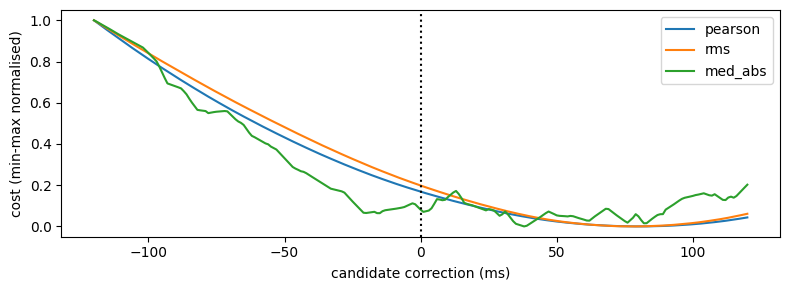


bootstrap 95% CI (ms)
pearson   | [  50.1,  103.6] width  53.5 | failed 5%
rms       | [  46.4,  101.9] width  55.6 | failed 5%
med_abs   | [ -21.7,   99.7] width 121.4 | failed 6%

inject s | pearson err | rms err | med_abs err
     -20 |    -0.00 |     0.00 |     0.00
     -10 |     0.00 |    -0.00 |    -0.00
      -5 |     0.00 |    -0.00 |    -0.00
       0 |     0.00 |     0.00 |     0.00
       5 |     0.00 |    -0.00 |     0.00
      10 |     0.00 |     0.00 |     0.00
      20 |     0.00 |    -0.00 |     0.00


In [38]:
# --- Step A: gate bad essential-matrix pairs, compare 3 cost functions, validate, bootstrap ---
LAT_MAX = 12.0
use2 = use & (lat < LAT_MAX)
print(f"pairs: {use.sum()} -> {use2.sum()} after lateral-angle gate (< {LAT_MAX} deg)")

Gfull = np.array([gyro_yaw_deg(tc, t) for t in TAUS])          # (n_tau, n_pairs)

def refine_min(cost, half=12):
    j = int(np.argmin(cost))
    if j < half or j > len(TAUS) - 1 - half: return np.nan     # minimum on the grid edge
    sl = slice(j - half, j + half + 1)
    p = np.polyfit(TAUS[sl] * 1e3, cost[sl], 2)
    return -p[1] / (2 * p[0]) if p[0] > 0 else np.nan          # ms

def est_all(G, y):
    """G: (n_tau, n) gyro yaw per candidate shift; y: visual yaw (n,). All costs are minimised."""
    Gc = G - G.mean(1, keepdims=True); yc = y - y.mean()
    pear = (Gc @ yc) / (np.linalg.norm(Gc, axis=1) * np.linalg.norm(yc))
    r = G - y
    curves = {"pearson": -pear,
              "rms":     np.sqrt((r ** 2).mean(1)),
              "med_abs": np.median(np.abs(r), axis=1)}
    return {k: (c, refine_min(c)) for k, c in curves.items()}

Gm, ym = Gfull[:, use2], vy2[use2]
out = est_all(Gm, ym)
print("\nestimator | grid argmin | refined (ms)")
for k, (c, e) in out.items():
    print(f"{k:9s} | {TAUS[np.argmin(c)]*1e3:+8.0f}    | {e:+8.1f}")

fig, ax = plt.subplots(figsize=(8, 3))
for k, (c, _) in out.items():
    ax.plot(TAUS * 1e3, (c - c.min()) / (c.max() - c.min()), label=k)
ax.axvline(0, c="k", ls=":"); ax.set_xlabel("candidate correction (ms)"); ax.set_ylabel("cost (min-max normalised)")
ax.legend(); plt.tight_layout(); plt.show()

# bootstrap over pairs
rng = np.random.default_rng(0); n2 = Gm.shape[1]
B = {k: [] for k in out}
for _ in range(1000):
    ii_ = rng.integers(0, n2, n2)
    for k, (_, e) in est_all(Gm[:, ii_], ym[ii_]).items(): B[k].append(e)
print("\nbootstrap 95% CI (ms)")
for k, v in B.items():
    v = np.array(v); ok = ~np.isnan(v)
    print(f"{k:9s} | [{np.percentile(v[ok], 2.5):6.1f}, {np.percentile(v[ok], 97.5):6.1f}] "
          f"width {np.ptp(np.percentile(v[ok], [2.5, 97.5])):5.1f} | failed {1 - ok.mean():.0%}")

# injected-shift validation (best-behaved estimator by CI width gets used going forward)
print("\ninject s | " + " | ".join(f"{k} err" for k in out))
base = {k: e for k, (_, e) in out.items()}
for s in [-20, -10, -5, 0, 5, 10, 20]:
    Gs = np.array([gyro_yaw_deg(tc + s / 1e3, t) for t in TAUS])[:, use2]
    r = est_all(Gs, ym)
    print(f"{s:8d} | " + " | ".join(f"{r[k][1] - (base[k] - s):8.2f}" for k in out))

In [39]:
Brms = np.array(B["rms"]); Brms = Brms[~np.isnan(Brms)]
imu_off = dict(est=out["rms"][1], lo=np.percentile(Brms, 2.5), hi=np.percentile(Brms, 97.5))

def health_v4(h, imu_off, v_rms=4.63, tol_cm=5.0, max_ci_ms=30.0):
    ms_per_cm = 10 / v_rms
    tol_ms = tol_cm * ms_per_cm
    est, lo, hi = imu_off["est"], imu_off["lo"], imu_off["hi"]
    h["imu_offset_ms"] = est; h["imu_offset_ci_ms"] = (lo, hi)
    h["imu_offset_cost_cm"] = abs(est) / ms_per_cm
    lo_abs = 0 if lo <= 0 <= hi else min(abs(lo), abs(hi))      # closest the CI gets to zero
    if lo_abs > tol_ms:                       v = "EXCEEDS"
    elif max(abs(lo), abs(hi)) <= tol_ms:     v = "OK"
    else:                                     v = "UNRESOLVED"
    if (hi - lo) > max_ci_ms: v += " (imprecise)"
    h["imu_offset_verdict"] = v
    pen = h["imu_offset_cost_cm"] / tol_cm if v.startswith("EXCEEDS") else 0
    h["score_v4"] = float(h["score"] * np.exp(-0.25 * pen))
    return h

h4 = health_v4(health_v3(timestamp_health(cam, lid), T_s=600), imu_off)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in h4.items()
       if k.startswith(("imu_", "score", "drift_verdict"))})

{'score': 95.27, 'drift_verdict': 'UNRESOLVED (session too short)', 'imu_offset_ms': np.float64(78.09), 'imu_offset_ci_ms': (np.float64(46.35132333951165), np.float64(101.94915695535047)), 'imu_offset_cost_cm': np.float64(36.16), 'imu_offset_verdict': 'EXCEEDS (imprecise)', 'score_v4': 15.63}


In [40]:
yaw_gt = np.unwrap(imu_clean[:, 5]); wu_ = imu_clean[:, 22]

def run_yaw_filter(t_cam, z_deg, mask, r_deg=0.2, q_yaw=1e-9, q_b=1e-10):
    ev = np.asarray(t_cam, float); gt = lambda t: np.interp(t, tg, yaw_gt)
    x = np.array([gt(ev[0]), 0.0, gt(ev[0])]); P = np.diag([1e-4, 1e-5, 1e-4])
    J = np.array([[1, 0, 0], [0, 1, 0], [1, 0, 0.0]]); H = np.array([[1, 0, -1.0]])
    t_last, errs = ev[0], []
    for i in range(1, len(ev)):
        t = ev[i]; dt = t - t_last
        w = np.interp(0.5 * (t + t_last), tg, wu_)
        x[0] += (w - x[1]) * dt
        F = np.array([[1, -dt, 0], [0, 1, 0], [0, 0, 1.0]])
        P = F @ P @ F.T + np.diag([q_yaw * dt, q_b * dt, 0])
        if mask[i - 1]:
            innov = np.radians(z_deg[i - 1]) - (x[0] - x[2])
            S = (H @ P @ H.T)[0, 0] + np.radians(r_deg) ** 2
            K = (P @ H.T)[:, 0] / S
            x = x + K * innov; P = P - np.outer(K, H @ P)
        x[2] = x[0]; P = J @ P @ J.T                      # clone yaw for the next interval
        errs.append(x[0] - gt(t)); t_last = t
    return np.degrees(np.array(errs))

e0 = out["rms"][1]
base = run_yaw_filter(tc + e0 / 1e3, vy2, np.zeros_like(use2))          # gyro only
print(f"gyro-only baseline: RMS yaw err {np.sqrt((base**2).mean()):.3f} deg, final {base[-1]:+.3f}\n")

print(" stamp error s | RMS yaw err (deg) | final err (deg) | vs gyro-only")
for s in [-e0, -50, -20, -10, -5, 0, 5, 10, 20, 50]:            # s = -e0 means raw, uncorrected stamps
    e = run_yaw_filter(tc + (e0 + s) / 1e3, vy2, use2)
    r = np.sqrt((e ** 2).mean())
    print(f"{s:+10.1f} ms | {r:16.3f}  | {e[-1]:+14.3f}  | {r / np.sqrt((base**2).mean()):10.2f}x")

gyro-only baseline: RMS yaw err 0.991 deg, final +0.704

 stamp error s | RMS yaw err (deg) | final err (deg) | vs gyro-only
     -78.1 ms |            0.730  |         +0.515  |       0.74x
     -50.0 ms |            0.579  |         +0.192  |       0.58x
     -20.0 ms |            0.560  |         -0.025  |       0.57x
     -10.0 ms |            0.589  |         -0.050  |       0.59x
      -5.0 ms |            0.601  |         -0.070  |       0.61x
      +0.0 ms |            0.606  |         -0.098  |       0.61x
      +5.0 ms |            0.624  |         -0.099  |       0.63x
     +10.0 ms |            0.642  |         -0.110  |       0.65x
     +20.0 ms |            0.648  |         -0.173  |       0.65x
     +50.0 ms |            0.741  |         -0.160  |       0.75x


In [41]:
# --- Step C: same cam<->IMU offset estimate on other 2011_09_26 drives (same calib, K0/D0 reused) ---
def process_drive(drive, date="2011_09_26", lat_max=12.0, n_boot=500):
    r = f"/kaggle/working/kitti/{date}/{date}_drive_{drive}_extract"
    if not os.path.exists(r):
        url = f"https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/{date}_drive_{drive}/{date}_drive_{drive}_extract.zip"
        zp = f"/kaggle/working/kitti/d{drive}.zip"
        urllib.request.urlretrieve(url, zp); zipfile.ZipFile(zp).extractall("/kaggle/working/kitti"); os.remove(zp)
    rd = lambda p: pd.to_datetime(pd.read_csv(p, header=None)[0]).astype("int64").values
    t_cam, t_imu = rd(f"{r}/image_00/timestamps.txt"), rd(f"{r}/oxts/timestamps.txt")
    pay = np.array([np.loadtxt(f) for f in sorted(glob.glob(f"{r}/oxts/data/*.txt"))])
    t_u, k = np.unique(t_imu, return_index=True); pay = pay[k]            # dedupe + sort, as in cell 5
    T0 = t_cam[0]; tc_, tg_ = (t_cam - T0) / 1e9, (t_u - T0) / 1e9
    wu_ = pay[:, 22]
    Cz_ = np.concatenate([[0], np.cumsum(0.5 * (wu_[1:] + wu_[:-1]) * np.diff(tg_))])
    gy = lambda tau: np.degrees(np.interp(tc_[1:] + tau, tg_, Cz_) - np.interp(tc_[:-1] + tau, tg_, Cz_))

    feats = []
    for p in sorted(glob.glob(f"{r}/image_00/data/*.png")):
        im = cv2.imread(p, cv2.IMREAD_GRAYSCALE); m = np.zeros_like(im); m[: int(0.8 * im.shape[0])] = 255
        feats.append(orb.detectAndCompute(im, m))
    res_ = [pair_cal(feats[i], feats[i + 1]) for i in range(len(feats) - 1)]   # from cell 31
    vy_ = SIGN * np.array([q[0][1] for q in res_]); inl_ = np.array([q[1] for q in res_]); lat_ = np.array([q[3] for q in res_])

    gaps = [(tg_[g], tg_[g + 1]) for g in np.where(np.diff(tg_) > 0.015)[0]]
    near = lambda a, b, m=0.25: any(a - m < g1 and b + m > g0 for g0, g1 in gaps)
    ok = ((tc_[:-1] - 0.18 > tg_[0]) & (tc_[1:] + 0.18 < tg_[-1]) & (inl_ >= 100)
          & np.isfinite(vy_) & np.isfinite(lat_) & (lat_ < lat_max)
          & np.array([not near(tc_[i], tc_[i + 1]) for i in range(len(vy_))]))
    G = np.array([gy(t) for t in TAUS])[:, ok]; y = vy_[ok]
    cost = lambda G_, y_: np.sqrt(((G_ - y_) ** 2).mean(1))
    est = refine_min(cost(G, y))
    rng = np.random.default_rng(0); n_ = len(y)
    bs = np.array([refine_min(cost(G[:, i], y[i])) for i in (rng.integers(0, n_, n_) for _ in range(n_boot))])
    bs = bs[~np.isnan(bs)]
    return dict(drive=drive, frames=len(t_cam), secs=round((t_cam[-1] - t_cam[0]) / 1e9, 1), pairs=int(ok.sum()),
                offset_ms=est, ci_lo=np.percentile(bs, 2.5) if len(bs) else np.nan,
                ci_hi=np.percentile(bs, 97.5) if len(bs) else np.nan, failed=1 - len(bs) / n_boot)

rows = []
for d in ["0005", "0011", "0014"]:        # 0005 = reproduces your result; add/replace drives as you like
    try: rows.append(process_drive(d))
    except Exception as e: print(d, "failed:", repr(e)[:150])
print(pd.DataFrame(rows).round(1).to_string(index=False))

drive  frames  secs  pairs  offset_ms  ci_lo  ci_hi  failed
 0005     160  16.4    108       78.1   48.5  101.6     0.0
 0011     239  24.6    117       64.2    9.9   98.5     0.0
 0014     320  33.0    285       71.9   55.9   84.9     0.0
